# E227 · Semantic adaptation with different learning strategies

**Complete** · E227 finished  
48/48 checkpoints and 960/960 branches  
Updated 2026-11-23T01:28:17+01:00 Stockholm

Eight E225 reference walks provide six common states each. Branches use four independent MAE mask draws per state and sustain their strategy for two complete chronological clips. The baseline reuses the unchanged encoder and decoder. All four trainable strategies take 96 steps at LR 7.5e-5 with batch size two. Replay replaces one incoming image per batch. Historical frames come from a 64-frame bank sampled across earlier clips. The regularizer adds twice the cosine distance to a cached branch-origin embedding on one historical frame per optimizer step.

External probes cover scene, weather, lighting, traffic light and pedestrian, with scene kNN reported separately. The same external images are also split into current-like and history-like panels. The split uses the pre-branch encoder’s similarity to 64 incoming and 64 past frames, then takes the two outer thirds within each class. These panels measure transfer to similar independent images. All labels, including the strata, stay in evaluation.

The semantic oracle chooses a strategy using the other three mask draws and is tested on the fourth. The primary readout is after two clips. The gate requires at least +0.25 pp over the strongest fixed strategy with the 95% walk interval above zero, repeatable held-out gains over No adaptation with the lower probability bound above 50%, and a fixed strategy with at least +0.25 pp above No adaptation on a semantic panel with a positive family-adjusted one-sided bound. Gains smaller than 0.10 pp are treated as ties in the repeatability check.

## +96 arrivals

| Strategy | Overall vs frozen (pp) | Current-like vs frozen (pp) | History-like vs frozen (pp) |
| --- | --- | --- | --- |
| Incoming MAE | +0.014 [-0.117, +0.160] | -0.116 [-0.320, +0.065] | +0.034 [-0.198, +0.279] |
| Historical replay MAE | +0.128 [-0.037, +0.283] | +0.021 [-0.152, +0.172] | +0.198 [+0.032, +0.382] |
| Encoder preservation | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Representation regularization | -0.017 [-0.122, +0.096] | -0.020 [-0.170, +0.154] | -0.021 [-0.161, +0.120] |
| No adaptation | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |

| Independent-draw gain (pp) | Best fixed strategy | Same-draw gain (pp) | Reproduced benefits | Repeatability (%) |
| --- | --- | --- | --- | --- |
| +0.171 [+0.089, +0.249] | Historical replay MAE | +0.187 [+0.111, +0.261] | 120/127 | +94.488 [+87.387, +99.324] |

## +192 arrivals

| Strategy | Overall vs frozen (pp) | Current-like vs frozen (pp) | History-like vs frozen (pp) |
| --- | --- | --- | --- |
| Incoming MAE | +0.017 [-0.061, +0.106] | -0.023 [-0.140, +0.086] | +0.052 [-0.094, +0.228] |
| Historical replay MAE | +0.169 [+0.009, +0.329] | +0.115 [-0.062, +0.314] | +0.246 [+0.021, +0.487] |
| Encoder preservation | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Representation regularization | +0.039 [-0.092, +0.168] | -0.005 [-0.222, +0.212] | +0.089 [-0.033, +0.208] |
| No adaptation | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |

| Independent-draw gain (pp) | Best fixed strategy | Same-draw gain (pp) | Reproduced benefits | Repeatability (%) |
| --- | --- | --- | --- | --- |
| +0.156 [+0.058, +0.274] | Historical replay MAE | +0.191 [+0.099, +0.300] | 115/124 | +92.742 [+84.685, +97.794] |

## Two-clip resource use per branch

| Strategy | Optimizer steps | Incoming | Replay | Extra anchor exposures | Image bank MiB | Target cache KiB | Training s | History setup s | Target setup s | Probe s |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Incoming MAE | 96 | 192 | 0 | 0 | 0.00 | 0.00 | 0.906 | 0.0000 | 0.0000 | 0.319 |
| Historical replay MAE | 96 | 96 | 96 | 0 | 3.00 | 0.00 | 0.906 | 0.0024 | 0.0000 | 0.319 |
| Encoder preservation | 96 | 192 | 0 | 0 | 0.00 | 0.00 | 0.597 | 0.0000 | 0.0000 | 0.027 |
| Representation regularization | 96 | 192 | 0 | 96 | 3.00 | 12.00 | 1.430 | 0.0024 | 0.0023 | 0.318 |
| No adaptation | 0 | 0 | 0 | 0 | 0.00 | 0.00 | 0.000 | 0.0000 | 0.0000 | 0.319 |

| Strategy | Held-out MSE | RankMe | scene | scene kNN | weather | lighting | traffic light | pedestrian |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Incoming MAE | 0.98106 | 6.09 | +0.092 | +0.157 | -0.080 | -0.043 | +0.001 | +0.114 |
| Historical replay MAE | 0.92905 | 6.60 | +0.331 | +0.090 | -0.003 | -0.005 | +0.177 | +0.343 |
| Encoder preservation | 0.97113 | 6.22 | +0.000 | +0.000 | +0.000 | +0.000 | +0.000 | +0.000 |
| Representation regularization | 0.96713 | 6.24 | +0.090 | +0.050 | +0.018 | -0.021 | +0.196 | -0.086 |
| No adaptation | 0.98578 | 6.22 | +0.000 | +0.000 | +0.000 | +0.000 | +0.000 | +0.000 |

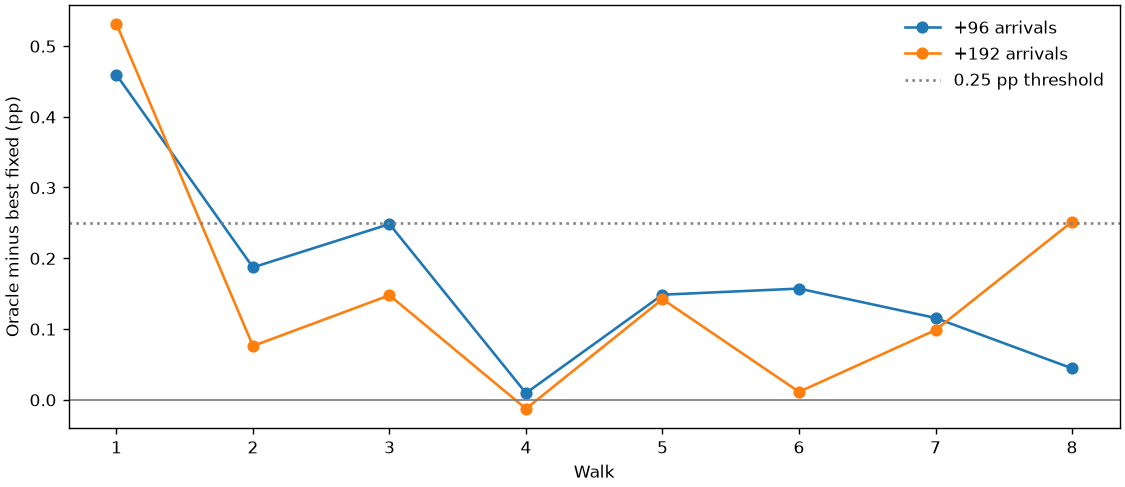

## Decision gate

**Did not pass.**

| Requirement | Met |
| --- | --- |
| opportunity | No |
| repeatable benefit | Yes |
| genuine semantic improvement | No |
| labels evaluation only | Yes |